# Дополнительный ноутбук 2. Тренды температур в крупнейших городах мира

**Файл:** `GlobalLandTemperaturesByMajorCity.csv` — среднемесячные температуры 100 крупнейших городов мира (49 стран). Период наблюдений различается по городам: самые ранние ряды начинаются в 1743 г., основная масса — в середине XIX века.

**Задача:** оценить скорость потепления в каждом городе, найти города-лидеры по росту температуры и сравнить динамику нескольких городов Европы и мира.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True

DATA_DIR = '../data'


In [7]:
mc = pd.read_csv(f'{DATA_DIR}/GlobalLandTemperaturesByMajorCity.csv',
                 usecols=['dt', 'AverageTemperature', 'City', 'Country'])
mc['dt'] = pd.to_datetime(mc['dt'])

print(f'Наблюдений: {len(mc):,}')
print(f'Городов: {mc["City"].nunique()}, стран: {mc["Country"].nunique()}')
print(f'Период: {mc["dt"].min().date()} — {mc["dt"].max().date()}')
mc.head(3)

Наблюдений: 239,177
Городов: 100, стран: 49
Период: 1743-11-01 — 2013-09-01


,dt,AverageTemperature,City,Country
0,1849-01-01,26.704,Abidjan,Côte D'Ivoire
1,1849-02-01,27.434,Abidjan,Côte D'Ivoire
2,1849-03-01,28.101,Abidjan,Côte D'Ivoire


## Скорость потепления по городам

Переводим месячные данные в годовые средние и считаем линейный тренд (°C за 100 лет) за период с 1900 года для каждого города.

In [8]:
def slope_per_century(series):
    """Линейный тренд ряда (индекс — годы) в °C за 100 лет."""
    s = series.dropna()
    x = s.index.values.astype(float)
    return np.polyfit(x - x.mean(), s.values, 1)[0] * 100

# Годовые средние по каждому городу
mc_ann = mc.groupby(['City', mc['dt'].dt.year])['AverageTemperature'].mean().unstack('City')

# Тренды с 1900 года (берём города с достаточным покрытием — не менее 80 лет данных)
city_trends = {}
for city in mc_ann.columns:
    s = mc_ann[city].loc[1900:]
    if s.dropna().shape[0] >= 80:
        city_trends[city] = slope_per_century(s)
city_trends = pd.Series(city_trends).sort_values(ascending=False)

print(f'Городов с оценкой тренда: {len(city_trends)}')
print('\nТоп-10 городов по скорости потепления, 1900–2013:')
city_trends.head(10).round(2)

Городов с оценкой тренда: 100

Топ-10 городов по скорости потепления, 1900–2013:


Mashhad      1.74
Harbin       1.64
Changchun    1.59
Moscow       1.59
Shenyang     1.48
Kiev         1.45
Baghdad      1.39
Peking       1.39
Tianjin      1.39
Montreal     1.38
dtype: float64

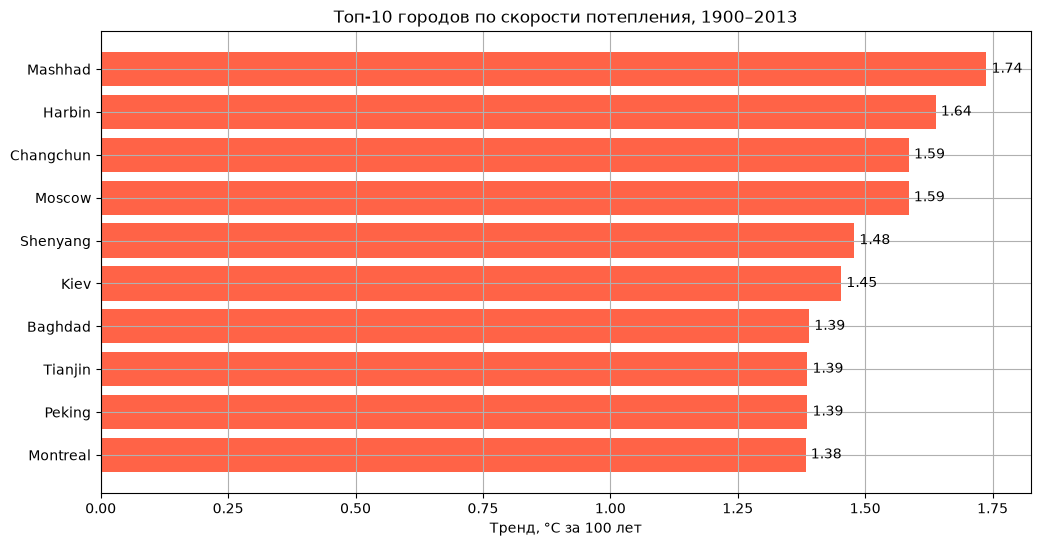

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
top10 = city_trends.head(10).sort_values()
ax.barh(top10.index, top10.values, color='tomato')
ax.set_title('Топ-10 городов по скорости потепления, 1900–2013')
ax.set_xlabel('Тренд, °C за 100 лет')
for i, v in enumerate(top10.values):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center')
plt.show()

В лидерах — города Северной Евразии и внутриконтинентальные мегаполисы. Москва (+1.59 °C/100 лет) входит в топ-5. Отчасти это общий климатический тренд континентальных широт, отчасти — эффект **«острова тепла»**: застройка, асфальт и антропогенные тепловыделения дополнительно нагревают крупные города.

## Динамика отдельных городов

Сравним годовые средние температуры нескольких городов Европы и мира со 10-летним сглаживанием.

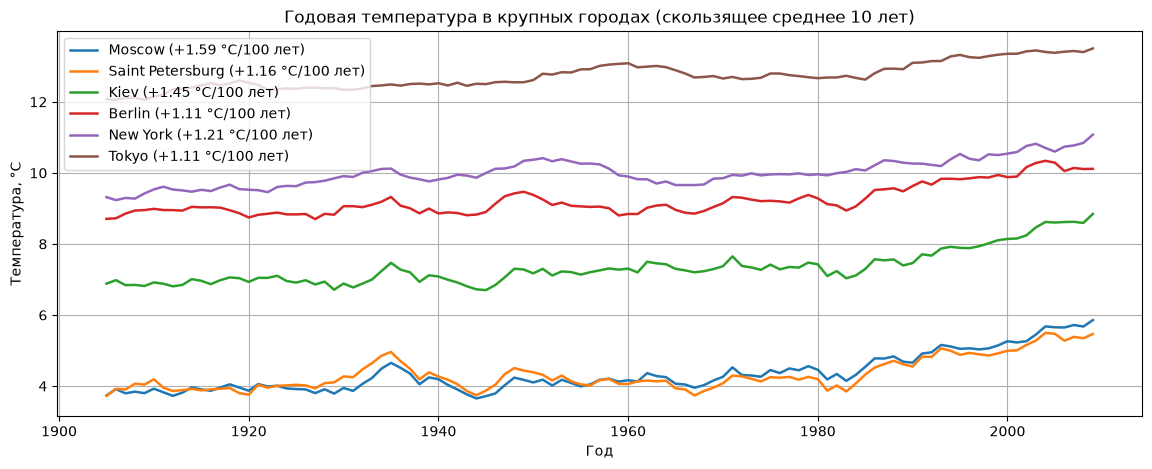

In [10]:
cities = ['Moscow', 'Saint Petersburg', 'Kiev', 'Berlin', 'New York', 'Tokyo']

fig, ax = plt.subplots()
for city in cities:
    s = mc_ann[city].loc[1900:]
    ax.plot(s.index, s.rolling(10, center=True).mean(), lw=1.8, label=f'{city} ({city_trends[city]:+.2f} °C/100 лет)')
ax.set_title('Годовая температура в крупных городах (скользящее среднее 10 лет)')
ax.set_xlabel('Год')
ax.set_ylabel('Температура, °C')
ax.legend()
plt.show()

## Выводы

1. Все 100 крупнейших городов мира показывают положительный тренд температуры за 1900–2013 гг. — потепление глобально и не зависит от конкретной локации.
2. Быстрее всего теплеют континентальные города северных широт: Мешхед (+1.74), Харбин (+1.64), Чанчунь и Москва (+1.59 °C/100 лет); медленнее всего — прибрежные города Южного полушария (например, Сидней, +0.79).
3. Городские ряды теплеют быстрее сельской местности из-за эффекта «острова тепла» — при интерпретации городских трендов это стоит учитывать.